# 집 수리 요청 프로세스 — Q3 예측 모델 · Q4 군집 / 개선 효과 / A/B 테스트

Q1~Q2에서 **단계 사이 시간의 74.8%가 점검 대기**이고 **수리 방식이 소요시간을 가른다**는 것을 확인했다.
여기서는 이 결과를 운영에 쓸 수 있는 형태로 바꾼다.

| 질문 | 방법 |
|---|---|
| 접수 직후, 오래 걸릴 요청을 미리 알 수 있나? | 분류 (로지스틱 / 랜덤 포레스트 / 그래디언트 부스팅) |
| 점검 후, 완료까지 며칠 남았나? | 회귀 (릿지 / 랜덤 포레스트 / 그래디언트 부스팅) |
| 시간이 새는 유형이 따로 있나? | K-Means 군집 |
| 점검 대기를 줄이면 얼마나 빨라지나? | 시나리오 시뮬레이션 |
| 개선안을 실험하려면 몇 건이 필요한가? | A/B 테스트 검정력 시뮬레이션 |

> 실행 전 `q1 ~ q2_3` 스크립트를 순서대로 실행해 `output/`을 만들어 둔다.

## 1. 예측 모델

**누수 방지**: 예측 시점에 모르는 정보(점검 결과, 담당자, 실제 경로, 수리 성공 여부)는 변수에서 뺐다.

**검증**: 접수 시각 순 앞 80% 학습 / 뒤 20% 테스트. 하이퍼파라미터는 학습 구간 안에서 `TimeSeriesSplit(5)` + `GridSearchCV`로 고르고, 테스트 구간은 마지막에 한 번만 사용했다. 모델 선택도 교차검증 점수로 했다.

[분석 대상] 927건 / 7일 초과 237건 (25.6%)
[분할] 학습 741건 (01-01~01-06) / 테스트 186건 (01-06~01-08)



[A] 접수 직후 '7일 초과' 분류 (튜닝은 학습 구간 CV, 점수는 테스트 구간)
       model                                                                     best_params  cv_auc  test_auc  test_pr_auc
    기준선(무작위)                                                                               -     NaN     0.500        0.253
기준선(수리방식 규칙)                                                                               -     NaN     0.826        0.514
     로지스틱 회귀                                                                        {'C': 1}   0.694     0.805        0.504
     랜덤 포레스트                    {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 500}   0.705     0.853        0.587
   그래디언트 부스팅 {'learning_rate': 0.1, 'max_depth': 2, 'max_iter': 300, 'min_samples_leaf': 30}   0.698     0.844        0.599

[A] 선택 모델: 랜덤 포레스트 / 확률 상위 30%를 '우선 점검'으로 지정하면
    테스트 구간 지정 75건 중 실제 7일 초과 41건 (정밀도 54.7%, 무작위 지정 시 25.3%) / 7일 초과 건의 87.2%를 미리 찾음
    E형 내부 구분력 AUC 0.562 (75건 중 7일 초과 41건, 규칙은 0.5)
    P형 내부 구분력 AUC 0.688


[A] 변수 중요도 (테스트 구간 permutation, AUC 감소량)
 RepairType       0.336
start_weekday    0.023
contact          0.003
start_hour       0.002
open_cases       0.000
survey_queue    -0.002



[B] 점검 완료 후 '남은 일수' 회귀 (MAE 단위: 일)
         model                                                                     best_params  cv_mae  test_mae  test_r2
기준선(수리방식별 중앙값)                                                                               -     NaN      0.90    0.081
         릿지 회귀                                                                  {'alpha': 100}    0.80      0.98    0.323
       랜덤 포레스트                   {'max_depth': 4, 'min_samples_leaf': 20, 'n_estimators': 300}    0.71      0.73    0.430
     그래디언트 부스팅 {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 300, 'min_samples_leaf': 30}    0.61      0.78    0.306



[B] 선택 모델: 그래디언트 부스팅 / 변수 중요도 (MAE 증가량, 일)
 RepairType             0.241
EstimatedRepairTime    0.135
survey_wait_h          0.053
survey_by              0.017
elapsed_d              0.006
RepairCode             0.002
open_cases             0.000
RepairInternally       0.000
contact               -0.000
start_hour            -0.006



저장 완료: /home/claude/zip/output/model_A_classification.csv, model_B_regression.csv, model_importance.csv, fig_model.png


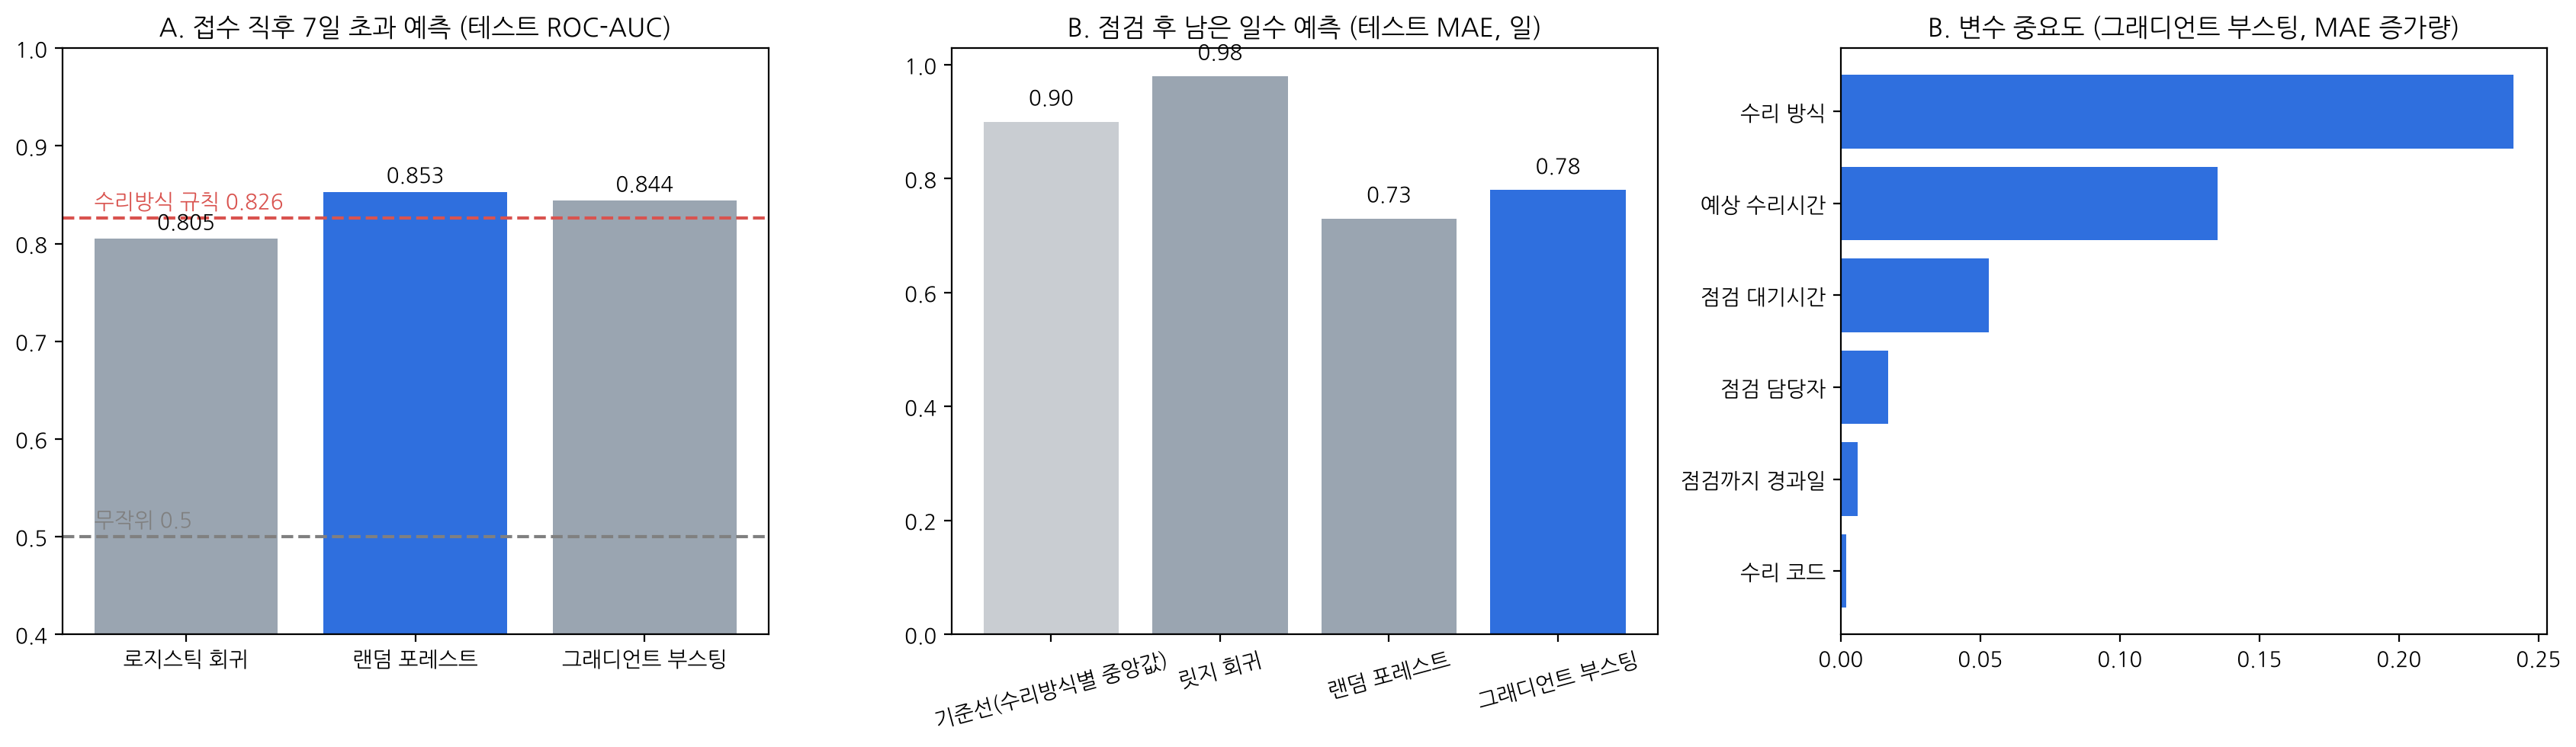

In [1]:
%run q3_model.py

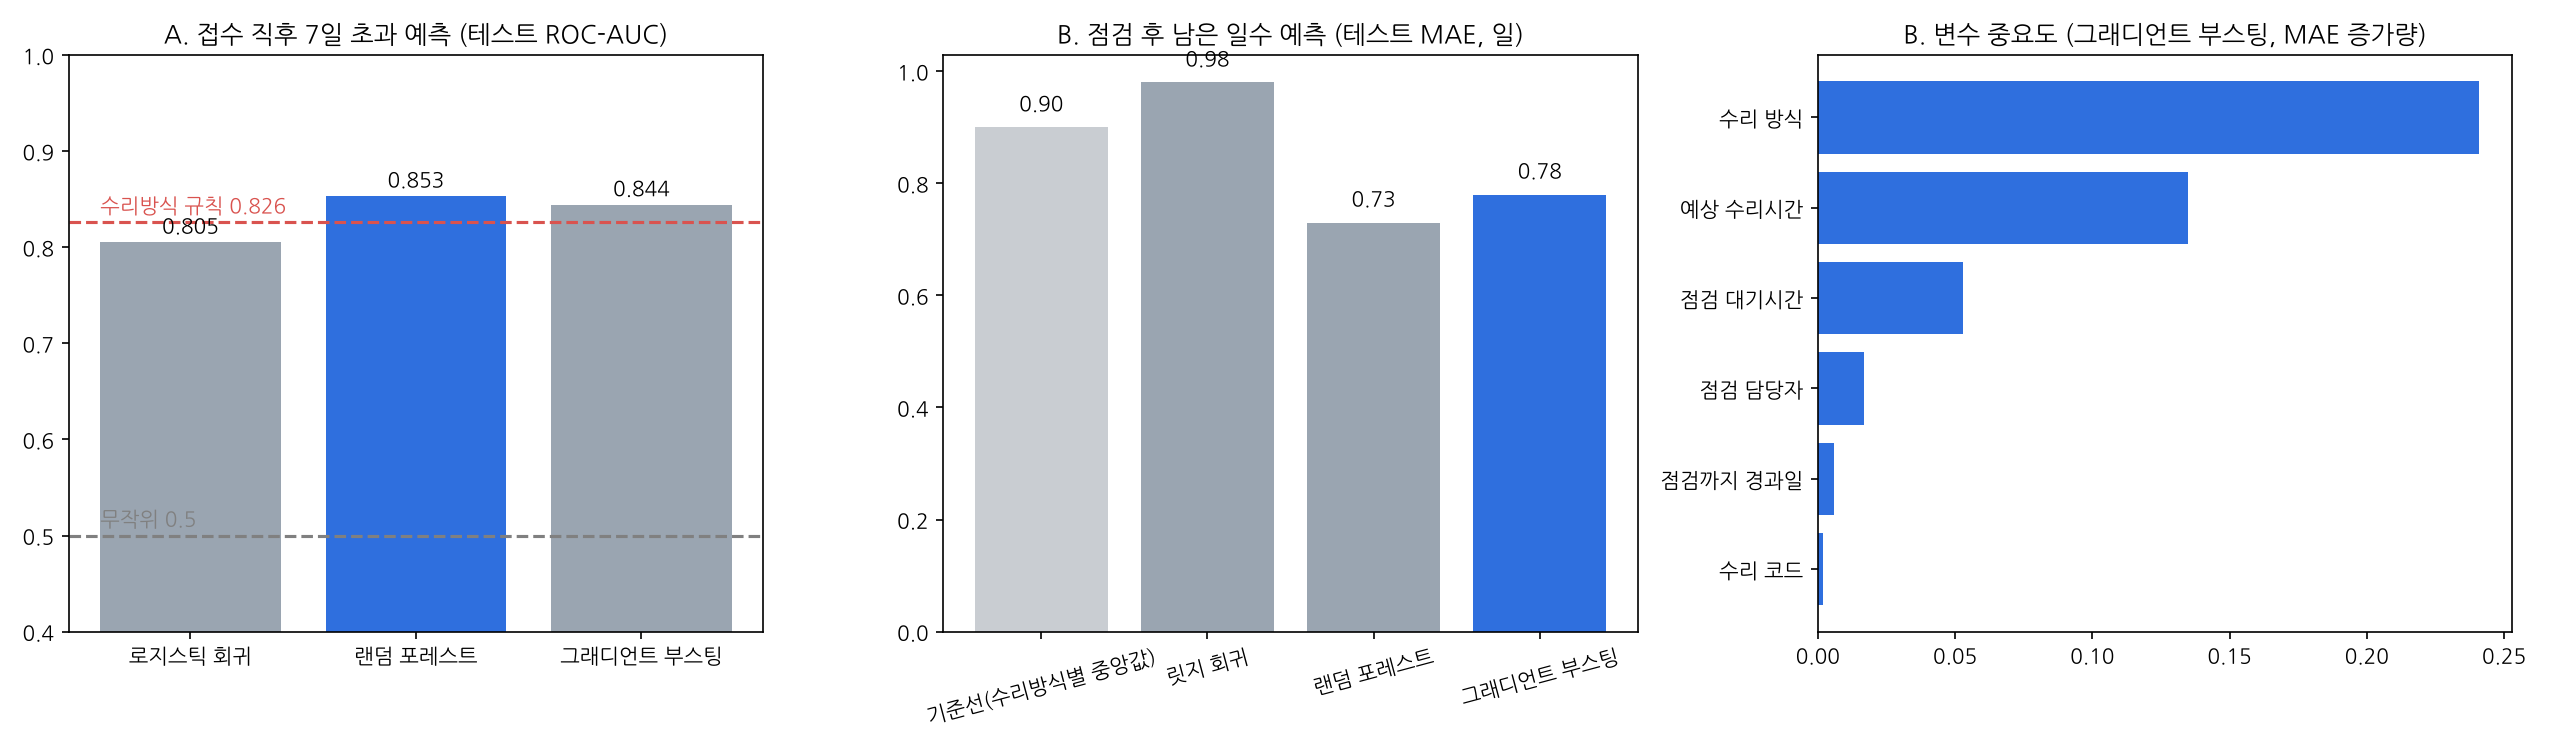

In [2]:
from IPython.display import Image
Image('output/fig_model.png')

**해석**
- 접수 직후 분류: 랜덤 포레스트 AUC 0.853. 하지만 **수리 방식만 쓰는 단순 규칙도 0.826**이다. 모델의 이득은 작고, 같은 방식 안에서의 구분력도 E형 0.56으로 약하다. → 접수 단계에서는 *E형을 우선 점검 대상으로 잡는 규칙*으로 충분하다. 복잡한 모델을 운영할 이유가 크지 않다는 것도 결론이다.
- 점검 후 회귀: 남은 일수 MAE가 기준선(수리 방식별 중앙값) 0.90일 → 0.73~0.78일로 **약 13~19% 개선**, R²는 0.08 → 0.31~0.43. 수리 방식 다음으로 *예상 수리시간*과 *점검 대기시간*이 중요했다.
- 교차검증 AUC(0.70)보다 테스트 AUC(0.85)가 높다. 테스트 구간(마지막 1.5일)에 E형 비중이 높아 규칙만으로도 잘 갈리는 구간이었기 때문이며, 데이터가 접수 8일치뿐이라 성능 수치는 보수적으로 봐야 한다.

## 2. 군집 · 개선 효과 · A/B 테스트

[군집 대상] 단계 시간이 모두 계산되는 케이스 561 / 927건


[실루엣 점수] {2: 0.232, 3: 0.225, 4: 0.246, 5: 0.257, 6: 0.251, 7: 0.234}

[군집 5개 프로필] 단계별 시간은 중앙값(시간)
          cases  접수_h  점검대기_h  점검작업_h  수리대기_h  수리작업_h  마감_h  소요일_중앙  일주일초과     비중     B     E     P
cluster                                                                                           
0          108  0.15    0.00    0.52    0.00    3.60  5.68    0.52   0.00  0.193  0.64  0.19  0.18
1          213  0.13   57.13    0.78    0.00    2.20  5.82    2.82   0.18  0.380  0.00  0.14  0.86
2           80  8.90   62.12    0.74    0.00    2.40  5.70    3.57   0.22  0.143  0.05  0.30  0.65
3           12  0.12   80.59    0.59   19.89   31.46  4.60    9.23   0.58  0.021  0.00  1.00  0.00
4          148  0.15  132.57    0.57   42.46    4.00  6.06    8.46   0.60  0.264  0.00  0.99  0.01

[군집별 단계 시간 비중]
           접수_h  점검대기_h  점검작업_h  수리대기_h  수리작업_h   마감_h
cluster                                              
0        0.078   0.102   0.039   0.044   0.331  0.405
1        0.003   0.885   0.0


[A/B 검정력] (현재 하루 약 127건 접수)
          단순 비교                   방식 보정                
        10% 감소  20% 감소  30% 감소  10% 감소  20% 감소  30% 감소
그룹당 건수                                                
50      0.0625  0.0975  0.2150  0.0525  0.1075  0.2325
100     0.0675  0.2400  0.3750  0.1050  0.2250  0.3925
200     0.1175  0.2950  0.6950  0.1100  0.3825  0.6625
300     0.1325  0.4825  0.8600  0.1225  0.5000  0.8325
400     0.2250  0.5825  0.9550  0.1875  0.5450  0.9425
600     0.2375  0.7625  0.9900  0.2450  0.7650  0.9825
800     0.3375  0.8900  0.9975  0.3325  0.8525  1.0000
1000    0.3900  0.9475  0.9975  0.3925  0.9350  1.0000
  [단순 비교] 10% 감소 효과를 80% 검정력으로: 그룹당 1000건 초과 필요
  [단순 비교] 20% 감소 효과를 80% 검정력으로: 그룹당 800건, 총 1600건 ≈ 12.6일치 접수
  [단순 비교] 30% 감소 효과를 80% 검정력으로: 그룹당 300건, 총 600건 ≈ 4.7일치 접수
  [방식 보정] 10% 감소 효과를 80% 검정력으로: 그룹당 1000건 초과 필요
  [방식 보정] 20% 감소 효과를 80% 검정력으로: 그룹당 800건, 총 1600건 ≈ 12.6일치 접수
  [방식 보정] 30% 감소 효과를 80% 검정력으로: 그룹당 300건, 총 600건 ≈ 4.7일치 접수



저장 완료: /home/claude/zip/output/cluster_profile.csv, improvement_simulation.csv, ab_power.csv, fig_cluster_ab_sim.png


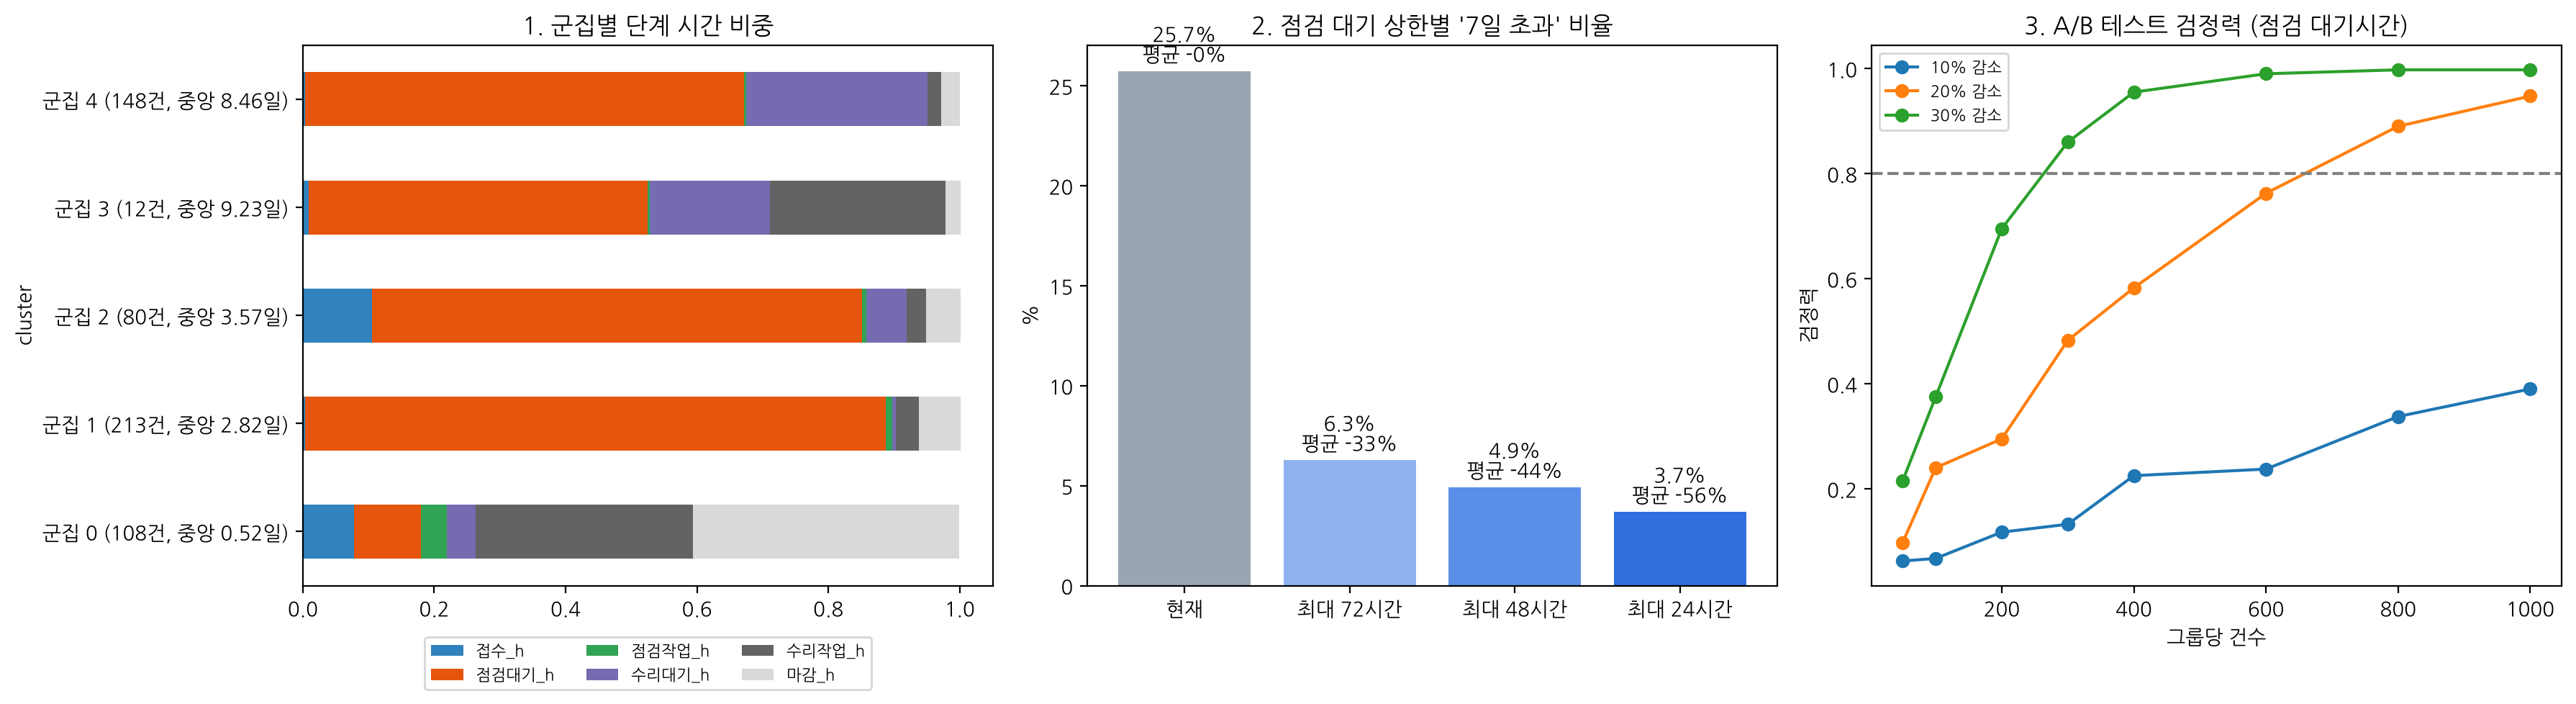

In [3]:
%run q4_cluster_ab_sim.py

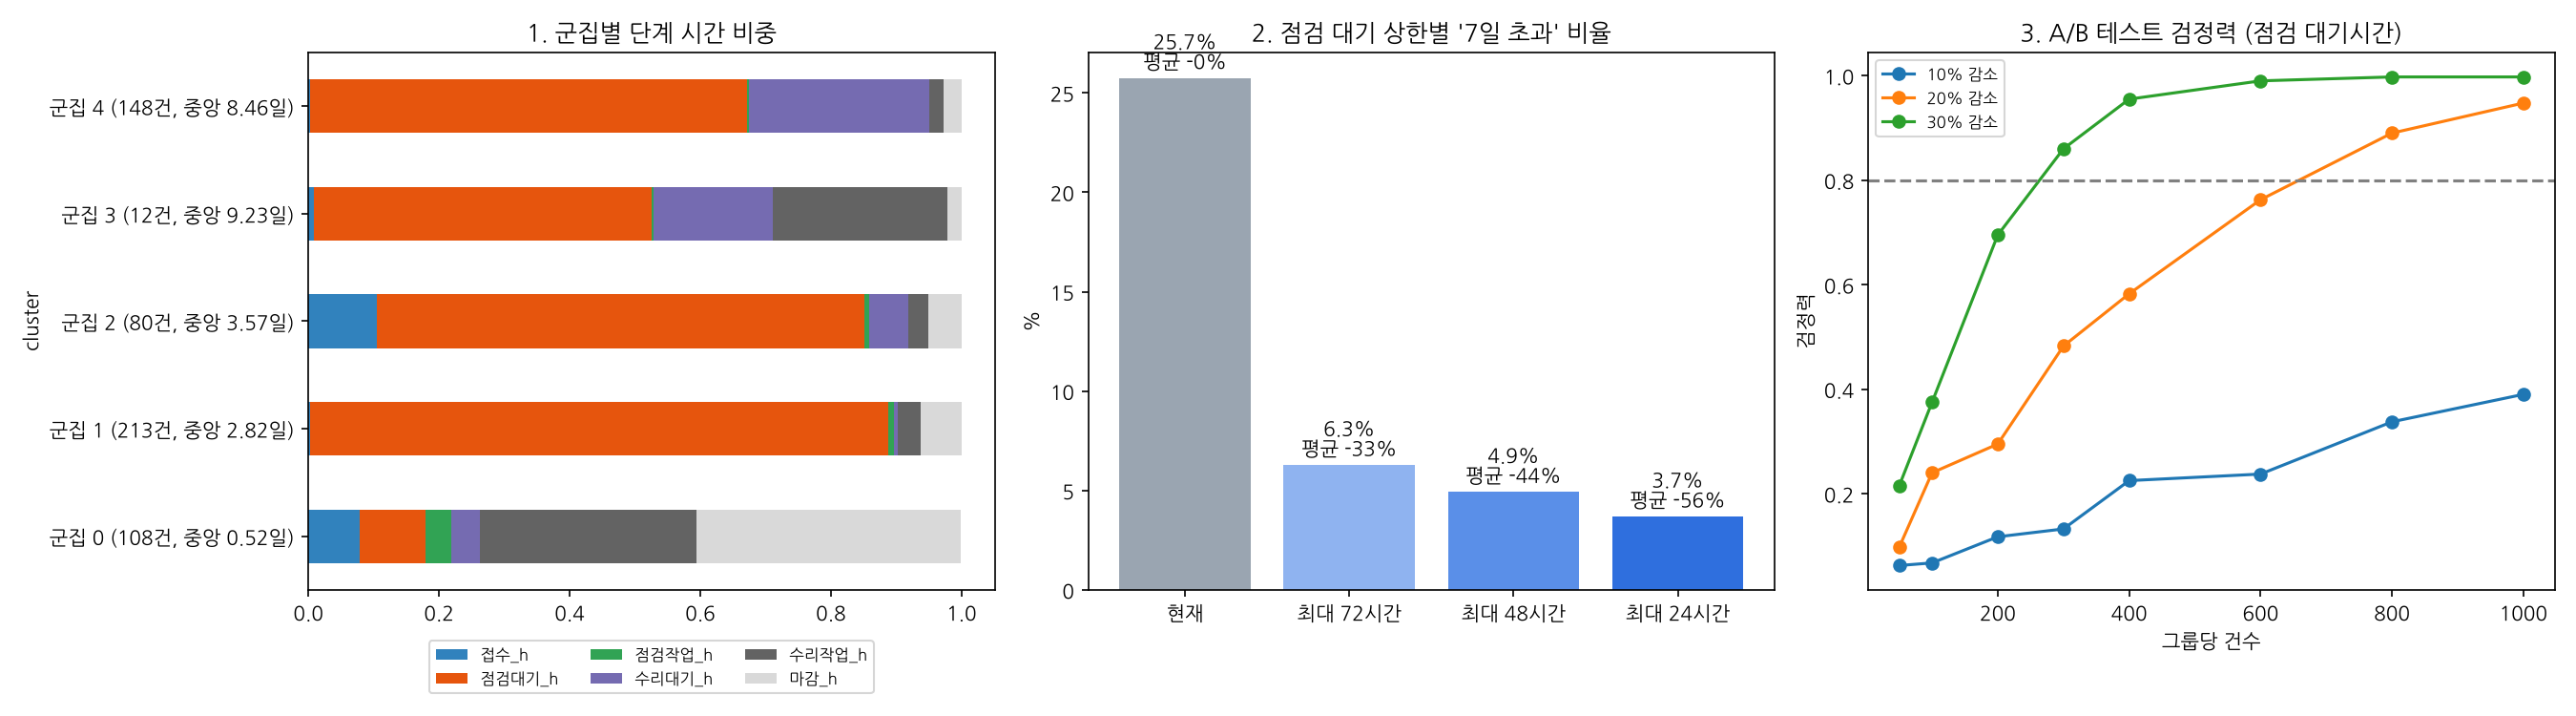

In [4]:
Image('output/fig_cluster_ab_sim.png')

**해석**
- **군집**: 실루엣 0.26으로 경계가 뚜렷하진 않지만 해석 가능한 5개 유형이 나왔다. 가장 문제인 유형은 **E형 장기 대기 군집(26%)** — 점검 대기 중앙값 133시간 + 수리 대기 42시간, 60%가 7일을 넘는다.
- **개선 효과**: 다른 단계는 그대로라고 가정하고, 점검 대기를 **최대 72시간으로 묶으면** 평균 소요시간 −33%, 7일 초과 건이 **25.7% → 6.3%**로 줄어든다.
- **A/B 테스트 설계** ('점검 지연 알림')
  - 배정: 접수 건 무작위 배정, 수리 방식 층화 / 1차 지표: 점검 대기시간 / 가드레일: 수리 성공률, 전체 소요시간, 담당자 처리 건수
  - 검정: Mann-Whitney U (분포가 치우침), 양측 α=0.05, 검정력 80%
  - 필요 표본: 30% 감소 효과는 그룹당 300건(약 5일치), 20%는 그룹당 800건(약 13일치). 10%는 1,000건으로도 부족 → 작은 효과는 실험 기간을 늘리거나 지표를 바꿔야 한다.
  - 수리 방식으로 보정해도 검정력은 거의 같았다. 대기시간 편차가 방식 *안에서* 크기 때문이다.